# 08a · Custeio por atividade (ABC) e custo de servir
**Pergunta:** quanto custa operar o SDC por ano, **em que atividade** o dinheiro vai, e quanto custa
servir cada canal (B2B × e-commerce) e cada zona (seco × resfriado × congelado)?

Custeio por atividade (*Activity-Based Costing*): cada recurso (pessoas, espaço, energia, capital,
perdas) é ligado a uma **atividade** (receber, armazenar, separar...), e cada atividade é distribuída
aos **objetos de custo** (canal, zona) pelo seu **direcionador** (paletes, linhas, pedidos, palete-dia).

Ano-base: nov/2025–out/2026, **escala cheia** (dados × 10). Premissas de custo em `config/parameters.yaml`
(`costs`, `labor_cost`, `productivity`). **São estimativas de ordem de grandeza.** O valor está na
estrutura e nas proporções; os valores exatos dependem de calibrar com a contabilidade real.
Fora do escopo: frete de entrega (custo de transporte) e impostos.

*EN summary: activity-based costing of the DC (full scale, base year) and cost-to-serve by channel
and temperature zone.*

In [1]:
import sys
sys.path.insert(0, "../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import flowsim as fs
from dcanalysis import q, save, savefig, log, params, ROOT, ZONE_COLORS

NB = "08a"
PH8 = ROOT / "reports" / "phase8"
P = params(); prm = fs.carregar_parametros(); slot = fs.carregar_slotting()
C, LC, PR = P["costs"], P["labor_cost"], P["productivity"]
INI, FIM = C["base_year"]
K = prm["scale"]                                   # escala cheia
# Horas-padrão do modelo -> horas PAGAS: ninguém trabalha 100% do turno (ocupação planejada e faltas, Fase 7)
FATOR_PAGO = 1 / (P["labor"]["utilization_target"] * (1 - P["labor"]["absenteeism"]))
c_op, c_ret = LC["picker_brl_h"] * FATOR_PAGO, LC["reach_truck_brl_h"] * FATOR_PAGO
print(f"Custo por hora-padrão: operador R$ {c_op:.2f}, retrátil R$ {c_ret:.2f} (fator de horas pagas {FATOR_PAGO:.2f})")
ZONAS = ["dry", "chilled", "frozen"]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

Custo por hora-padrão: operador R$ 34.67, retrátil R$ 55.73 (fator de horas pagas 1.24)


## 1. Volumes do ano-base (direcionadores)

In [2]:
rec = q("""SELECT zone, COUNT(*) AS paletes, SUM(status = 'ACCEPTED') AS aceitos
           FROM fact_receipt WHERE arrival_ts >= :i AND arrival_ts < :f GROUP BY zone""", i=INI, f=FIM).set_index("zone") * K
pal_dia = q("""SELECT zone, SUM(rack_pallets + overflow_pallets) AS palete_dias
               FROM fact_occupancy_daily WHERE date_key >= :i AND date_key < :f GROUP BY zone""",
            i=INI, f=FIM).set_index("zone") * K
reab = q("""SELECT s.zone, COUNT(*) AS reabastecimentos FROM fact_movement m JOIN dim_sku s ON s.sku_id = m.sku_id
            WHERE m.movement_type = 'REPLENISH' AND m.date_key >= :i AND m.date_key < :f GROUP BY s.zone""",
         i=INI, f=FIM).set_index("zone") * K
vend = q("""SELECT f.channel, s.zone, COUNT(*) AS linhas, COUNT(DISTINCT f.order_id) AS pedidos,
                   SUM(f.qty_picked_units) AS unidades, SUM(f.qty_picked_units * s.unit_price) AS receita,
                   SUM(1.0 * f.qty_picked_units / (s.units_per_case * s.cases_per_pallet)) AS paletes_saida
            FROM fact_order_line f JOIN dim_sku s ON s.sku_id = f.sku_id
            WHERE f.order_date >= :i AND f.order_date < :f GROUP BY 1, 2""", i=INI, f=FIM).set_index(["channel", "zone"])
pedidos_canal = q("""SELECT channel, COUNT(DISTINCT order_id) AS pedidos FROM fact_order_line
                     WHERE order_date >= :i AND order_date < :f GROUP BY 1""", i=INI, f=FIM).set_index("channel") * K
vend = vend * K
devol = q("""SELECT f.channel, s.zone, COUNT(*) AS devolucoes FROM fact_return r
             JOIN fact_order_line f ON f.order_line_id = r.order_line_id JOIN dim_sku s ON s.sku_id = r.sku_id
             WHERE r.return_date >= :i AND r.return_date < :f GROUP BY 1, 2""", i=INI, f=FIM).set_index(["channel", "zone"]) * K
cont = q("""SELECT l.zone, COUNT(*) AS contagens FROM fact_cycle_count c JOIN dim_location l ON l.location_id = c.location_id
            WHERE c.count_date >= :i AND c.count_date < :f GROUP BY 1""", i=INI, f=FIM).set_index("zone") * K
perdas = q("""SELECT s.zone, REPLACE(m.movement_type, 'WRITE_OFF_', '') AS tipo, SUM(m.qty_units * s.unit_cost) AS custo
              FROM fact_movement m JOIN dim_sku s ON s.sku_id = m.sku_id
              WHERE m.movement_type LIKE 'WRITE_OFF_%' AND m.date_key >= :i AND m.date_key < :f GROUP BY 1, 2""",
           i=INI, f=FIM).pivot_table(index="zone", columns="tipo", values="custo", aggfunc="sum").fillna(0) * K
estoque = q("""SELECT s.zone, SUM(i.qty_units * s.unit_cost) / COUNT(DISTINCT i.date_key) AS valor_medio
               FROM fact_inventory_daily i JOIN dim_sku s ON s.sku_id = i.sku_id
               WHERE i.date_key >= :i AND i.date_key < :f GROUP BY 1""", i=INI, f=FIM).set_index("zone") * K
print("Pedidos/ano:", pedidos_canal.pedidos.to_dict())
vend[["linhas", "unidades", "receita", "paletes_saida"]].round(0)

Pedidos/ano: {'B2B': 186170, 'ECOM': 459110}


linhas   unidades          receita  paletes_saida
channel zone                                                       
B2B     chilled  1635010   78030870   942,647,184.00      76,994.00
        dry      3700720  163185730 1,385,903,441.00     160,880.00
        frozen    627840   16078330   410,836,768.00      40,968.00
ECOM    chilled   298310     341300     4,565,684.00         451.00
        dry      1453250    1606090    15,329,941.00       2,317.00
        frozen     80340      98160     3,019,428.00         342.00

## 2. Custo de cada atividade, por zona
| Atividade | Recursos | Cálculo |
|---|---|---|
| Recebimento | conferente + retrátil do dia | paletes × (descarga + putaway) |
| Armazenagem | aluguel, energia, estrutura | área e volume da zona; estrutura depreciada |
| Reabastecimento | retrátil | reabastecimentos × tempo |
| Separação | separador + retrátil da noite | horas do modelo calibrado (Fase 6/7) |
| Embalagem e expedição | operador | pedidos e-commerce × embalagem + paletes expedidos × carregamento |
| Devoluções e inventário | operador | linhas devolvidas e endereços contados × tempo |
| Perdas | produto baixado | baixas a custo (vencimento, frio, recall, avaria) |
| Capital em estoque | custo de oportunidade | estoque médio × taxa anual |
| Indiretos | supervisão, staff, área de apoio | rateados pelo custo de mão de obra direta |

In [3]:
custos = pd.DataFrame(0.0, index=ZONAS, columns=[])

# Recebimento: descarga (conferente) + putaway (retrátil)
custos["recebimento"] = pd.Series({z: rec.loc[z, "paletes"] * prm["unload_min"][z] / 60 * c_op
                                   + rec.loc[z, "aceitos"] * prm["putaway_min"] / 60 * c_ret for z in ZONAS})

# Armazenagem: aluguel + energia + depreciação da estrutura
area, aluguel = C["area_m2"], C["rent_brl_m2_month"]
tarifa, kwh = C["energy_tariff_brl_kwh"], C["energy_kwh_m3_year"]
vol = {"chilled": 30 * 63 * C["chamber_height_m"], "frozen": 24 * 63 * C["chamber_height_m"]}
energia_kwh = {"dry": area["dry"] * C["energy_dry_kwh_m2_year"],
               "chilled": vol["chilled"] * kwh["chilled"] + C["antechamber_m3"] / 2 * kwh["antechamber"],
               "frozen": vol["frozen"] * kwh["frozen"] + C["antechamber_m3"] / 2 * kwh["antechamber"]}
posicoes = P["facility"]["zones"]
custos["aluguel"] = pd.Series({z: area[z] * (aluguel["dry"] if z == "dry" else aluguel["cold"]) * 12 for z in ZONAS})
custos["energia"] = pd.Series({z: energia_kwh[z] * tarifa for z in ZONAS})
custos["estrutura"] = pd.Series({z: posicoes[z]["pallet_positions"] * C["racking_capex_brl_position"]["selective"]
                                 / C["racking_life_years"] for z in ZONAS})

# Reabastecimento
custos["reabastecimento"] = pd.Series({z: reab.loc[z, "reabastecimentos"] * PR["replenish_time_s"] / 3600 * c_ret
                                       for z in ZONAS})

# Separação: horas do modelo calibrado por canal x zona
lin = fs.preparar_linhas(INI, FIM, slot, prm)
sep = lin.groupby(["channel", "zone"]).agg(pick_s=("pick_s", "sum"), ret_s=("retratil_s", "sum"))
sub = fs.preparar_pedidos(INI, FIM, slot, prm)
sep["viagem_s"] = sub.assign(v=prm["tour_setup_s"] + 2 * sub.dist_max / prm["walk"]).groupby(["channel", "zone"]).v.sum()
sep["custo"] = ((sep.pick_s + sep.viagem_s + sep.ret_s) / 3600 * c_op + sep.ret_s / 3600 * c_ret) * K
custo_sep_cz = sep.custo                                             # por canal x zona (separador espera a retrátil)
custos["separacao"] = custo_sep_cz.groupby(level="zone").sum()

# Embalagem (e-commerce) e carregamento (paletes expedidos)
emb_cz = pd.Series(0.0, index=vend.index)
eco = vend.xs("ECOM", level="channel")
emb_cz.loc["ECOM"] = (pedidos_canal.loc["ECOM", "pedidos"] * C["packing_min_per_ecom_order"] / 60 * c_op
                      * eco.linhas / eco.linhas.sum()).values       # pedidos rateados às zonas pelas linhas
carr_cz = vend.paletes_saida * C["loading_min_per_pallet_out"] / 60 * c_op
custos["embalagem_expedicao"] = (emb_cz + carr_cz).groupby(level="zone").sum()

# Devoluções e inventário cíclico
dev_cz = devol.devolucoes.reindex(vend.index).fillna(0) * C["return_min_per_line"] / 60 * c_op
custos["devolucoes"] = dev_cz.groupby(level="zone").sum()
custos["inventario_ciclico"] = cont.contagens * C["count_min_per_location"] / 60 * c_op

# Perdas e capital em estoque
custos["perdas"] = perdas.sum(axis=1)
custos["capital_estoque"] = estoque.valor_medio * C["inventory_carrying_rate_year"]

# Indiretos: supervisão (1 líder / 15 diretos) + staff + área de apoio, rateados pela mão de obra direta
mo_direta = custos[["recebimento", "reabastecimento", "separacao", "embalagem_expedicao", "devolucoes", "inventario_ciclico"]].sum(axis=1)
horas_pessoa_ano = P["labor"]["shift_hours"] * P["labor"]["nights_per_month"] * 12
pessoas_diretas = (mo_direta / c_op).sum() / horas_pessoa_ano      # aproximação em "pessoas-equivalentes"
indireto_total = (pessoas_diretas / C["supervisor_span"] * C["supervisor_brl_month"] * 12
                  + C["indirect_staff_brl_year"]
                  + area["support"] * aluguel["dry"] * 12 + area["support"] * C["energy_dry_kwh_m2_year"] * tarifa)
custos["indiretos"] = indireto_total * mo_direta / mo_direta.sum()
print(f"Pessoas diretas (equivalente): ~{pessoas_diretas:,.0f} | indiretos: R$ {indireto_total / 1e6:,.1f} mi/ano")

custos.loc["Total"] = custos.sum()
custos["TOTAL"] = custos.sum(axis=1)
save(custos.reset_index(names="zona").round(0), "08a_custo_atividade_zona", out=PH8)
(custos / 1e6).round(2)

Pessoas diretas (equivalente): ~176 | indiretos: R$ 4.9 mi/ano


,recebimento,aluguel,energia,estrutura,reabastecimento,separacao,embalagem_expedicao,devolucoes,inventario_ciclico,perdas,capital_estoque,indiretos,TOTAL
dry,1.75,4.75,0.23,0.41,0.28,7.74,0.60,0.25,0.03,3.04,3.74,3.45,26.28
chilled,0.85,1.62,0.72,0.07,0.12,1.69,0.20,0.08,0.00,24.28,0.97,0.95,31.55
frozen,0.45,1.37,0.95,0.06,0.06,1.04,0.09,0.03,0.00,33.54,0.71,0.54,38.84
Total,3.06,7.74,1.91,0.54,0.46,10.47,0.89,0.36,0.04,60.85,5.42,4.94,96.66


Custo total do CD: R$ 96.7 mi/ano = 3.5% da receita movimentada (R$ 2.76 bi)


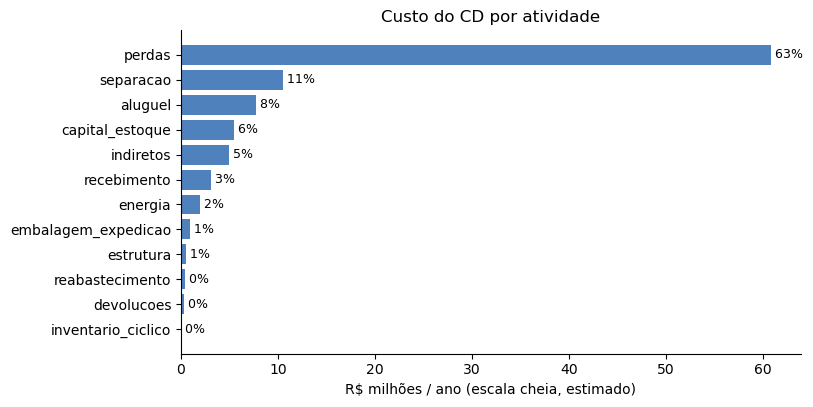

In [4]:
# Barras horizontais: participação de cada atividade no custo total (ranking de muitas categorias).
part = custos.loc["Total"].drop("TOTAL").sort_values()
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(part.index, part / 1e6, color="#4F81BD")
for y, v in enumerate(part):
    ax.text(v / 1e6, y, f" {100 * v / part.sum():.0f}%", va="center", fontsize=9)
ax.set_xlabel("R$ milhões / ano (escala cheia, estimado)"); ax.set_title("Custo do CD por atividade")
savefig(fig, "08a_custo_atividade", out=PH8)
total = custos.loc["Total", "TOTAL"]
receita = vend.receita.sum()
print(f"Custo total do CD: R$ {total / 1e6:,.1f} mi/ano = {100 * total / receita:.1f}% da receita movimentada "
      f"(R$ {receita / 1e9:,.2f} bi)")

In [5]:
# Perdas por tipo e zona (R$ mi/ano): o maior bloco de custo merece ser aberto
(perdas / 1e6).round(2)

tipo,COLD_CHAIN,DAMAGE,EXPIRY,RECALL
zone,,,,
chilled,22.65,0.12,1.51,0.00
dry,0.00,0.73,0.46,1.85
frozen,33.36,0.17,0.00,0.00


**Atenção às perdas:** elas somam a maior parte do custo do CD, e quase tudo vem da **cadeia do frio**
(congelado e resfriado). Nos dados sintéticos a perda no frio é alta para padrões de mercado (em
operações maduras costuma ficar abaixo de 1–2% da receita do frio). Mesmo descontando isso, a
conclusão se mantém: **cada ponto de perda no frio vale mais que toda a otimização de mão de obra**.
Por isso a cadeia do frio é prioridade 1 no programa de custos (Fases 9 e 10).

## 3. Indicadores unitários por zona

In [6]:
uni = pd.DataFrame({
    "custo_por_palete_dia": custos.loc[ZONAS, ["aluguel", "energia", "estrutura"]].sum(axis=1) / pal_dia.palete_dias,
    "energia_por_palete_mes": custos.loc[ZONAS, "energia"] / (pal_dia.palete_dias / 12),
    "custo_por_palete_recebido": custos.loc[ZONAS, "recebimento"] / rec.paletes,
    "perdas_pct_receita": 100 * custos.loc[ZONAS, "perdas"] / vend.receita.groupby(level="zone").sum(),
    "custo_total_pct_receita": 100 * custos.loc[ZONAS, "TOTAL"] / vend.receita.groupby(level="zone").sum(),
})
save(uni.reset_index(names="zona").round(3), "08a_indicadores_zona", out=PH8)
uni.round(2)

,custo_por_palete_dia,energia_por_palete_mes,custo_por_palete_recebido,perdas_pct_receita,custo_total_pct_receita
chilled,3.60,12.97,6.11,2.56,3.33
dry,1.46,0.75,5.40,0.22,1.88
frozen,4.19,20.15,6.47,8.10,9.38


**Leitura:** o palete-dia no frio custa **várias vezes** o do seco (aluguel de câmara + energia), e as
**perdas** pesam muito mais no frio. É por isso que densidade (S01) e disciplina de cadeia do frio
(Fases 4 e 9) valem mais no frio que no seco.

## 4. Custo de servir por canal
Atividades de zona (recebimento, armazenagem, reabastecimento, perdas, capital, inventário) são
rateadas aos canais pelas **unidades expedidas** de cada canal na zona. Separação, embalagem,
carregamento e devoluções vão **direto** ao canal que as consome.

In [7]:
partes_zona = ["recebimento", "aluguel", "energia", "estrutura", "reabastecimento", "perdas",
               "capital_estoque", "inventario_ciclico"]
share_und = vend.unidades / vend.unidades.groupby(level="zone").transform("sum")
cts = pd.DataFrame(index=vend.index)
for a in partes_zona:
    cts[a] = share_und * vend.index.get_level_values("zone").map(custos.loc[ZONAS, a]).values
cts["separacao"] = custo_sep_cz.reindex(vend.index).fillna(0)
cts["embalagem_expedicao"] = (emb_cz + carr_cz).reindex(vend.index)
cts["devolucoes"] = dev_cz.reindex(vend.index)
mo_cz = cts[["recebimento", "reabastecimento", "separacao", "embalagem_expedicao", "devolucoes", "inventario_ciclico"]].sum(axis=1)
cts["indiretos"] = indireto_total * mo_cz / mo_cz.sum()
cts["total"] = cts.sum(axis=1)
assert abs(cts.total.sum() - total) / total < 1e-6, "o custo de servir deve fechar com o custo total"

canal = cts.groupby(level="channel").sum()
vc = vend.groupby(level="channel").sum()
custo_servir = pd.DataFrame({
    "custo_total_mi": canal.total / 1e6,
    "custo_por_pedido": canal.total / pedidos_canal.pedidos,
    "custo_por_linha": canal.total / vc.linhas,
    "custo_por_unidade": canal.total / vc.unidades,
    "custo_pct_receita": 100 * canal.total / vc.receita,
})
save(custo_servir.reset_index().round(3), "08a_custo_servir_canal", out=PH8)
save(cts.reset_index().round(0), "08a_custo_servir_canal_zona", out=PH8)
custo_servir.round(2)

,custo_total_mi,custo_por_pedido,custo_por_linha,custo_por_unidade,custo_pct_receita
channel,,,,,
B2B,92.85,498.71,15.57,0.36,3.39
ECOM,3.82,8.32,2.08,1.87,16.66


,recebimento,aluguel,energia,estrutura,reabastecimento,perdas,capital_estoque,inventario_ciclico,separacao,embalagem_expedicao,devolucoes,indiretos
channel,,,,,,,,,,,,
B2B,3.30,8.30,2.00,0.60,0.50,65.20,5.80,0.00,9.20,0.50,0.20,4.40
ECOM,0.60,1.60,0.30,0.10,0.10,8.90,1.20,0.00,50.80,10.60,4.40,21.50


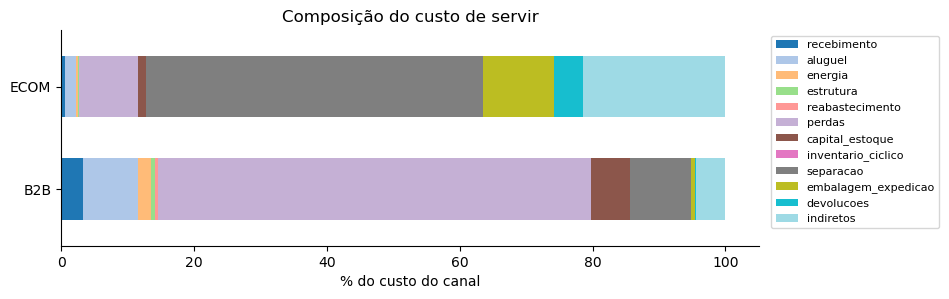

In [8]:
# Barras empilhadas 100%: composição do custo de cada canal (mostra o que pesa em cada um).
comp = canal.drop(columns="total").div(canal.total, axis=0) * 100
fig, ax = plt.subplots(figsize=(9, 2.8))
comp.plot.barh(stacked=True, ax=ax, width=0.6, colormap="tab20")
ax.set_xlabel("% do custo do canal"); ax.set_ylabel(""); ax.legend(bbox_to_anchor=(1.01, 1), fontsize=8)
ax.set_title("Composição do custo de servir")
savefig(fig, "08a_custo_servir_composicao", out=PH8)
comp.round(1)

**Leitura:**
- O **e-commerce** custa muito mais **por unidade** e **por real vendido**: pedidos pequenos geram uma
  viagem de separação e uma embalagem para poucas unidades. O B2B dilui o custo em pedidos grandes.
- Por isso as ações de e-commerce (carrinho em lote da Fase 7) atacam o canal de maior custo unitário.
  Uma política comercial (pedido mínimo ou frete por faixa) é uma decisão de negócio, que fica para a
  diretoria com estes números.
- Perdas e capital em estoque são uma fatia relevante do custo total, o que conecta custos à política de
  estoque (Fase 4) e à cadeia do frio.

In [9]:
log(NB, f"custeio ABC ano-base {INI}..{FIM} em escala cheia (x{K}); separação pelo modelo calibrado; "
        f"indiretos rateados pela MO direta; custo de servir por canal (rateio por unidades na zona)")